# CS 451/651: Data-Intensive Distributed Computing (Fall 2025)
# Assignment 4: Machine Learning

## 1. Download and Unpack Data

Download and unpack the feature files referenced in the <a href="https://lintool.github.io/cs451-2025f/assignments/assignment4.html">assignment landing page</a>.
Define the `data_path` accordingly:

In [1]:
# Change path accordingly:
data_path = "/Users/andy/Documents/cs651/a4"

# Needed for later, so just import here:
import os

Sanity check, make sure you can access the files:

In [2]:
!wc {data_path}/spam.train.txt
!wc {data_path}/spam.test.txt

     756 3864697 26642354 /Users/andy/Documents/cs651/a4/spam.train.txt
   25329 165166355 1138719624 /Users/andy/Documents/cs651/a4/spam.test.txt


## 2. Loading Training Data

Per the <a href="https://lintool.github.io/cs451-2025f/assignments/assignment4.html">assignment landing page</a>, you need to figure out how many features there are, i.e., `dim`.

<font color="red">**Below, you'll have to write some code. 
In your submission, please make sure we can clearly see the output of running the code.**</font>

In [3]:
# codecell_2a (keep this id for tracking purposes)
max_feature = 0

with open(f"{data_path}/spam.test.txt")as f:
    for line in f:
        parts = line.strip().split()
        feature_ids = [int(x) for x in parts[2:]]
        m = max(feature_ids)
        if m > max_feature:
            max_feature = m

with open(f"{data_path}/spam.train.txt")as f:
    for line in f:
        parts = line.strip().split()
        feature_ids = [int(x) for x in parts[2:]]
        m = max(feature_ids)
        if m > max_feature:
            max_feature = m

print("maximum feature:", max_feature)
print("dim =", max_feature + 1)



maximum feature: 1000081
dim = 1000082


Set `dim` below (obviously, set it to the correct value):

In [4]:
# codecell_2b (keep this id for tracking purposes)

dim = 1000082

Your next task is to create a file called `A4_load_data.py` and in the file define a function `load_data` that has the following signature:

```python
def load_data(file: str, dim: int) -> (csr_matrix, ndarray):
```

That is, the function takes in a file (e.g., one of the feature files above) and the number of dimensions of the feature vector `dim`, and returns `X` and `y`.
As discussed in lecture, these correspond to the (desired) inputs and outputs of the classifier, respectively:

+ `X` has the type `csr_matrix` (representing the feature vectors)
+ `y` has the type `ndarray` (representing the labels: 1=spam, 0=ham)

<font color="red">**Below, you'll have to write some code, but in a separate file.**</font>

In [5]:
from A4_load_data import load_data

If you've done the implementation above correctly, the below cell should just run.

In [6]:
X_train, y_train = load_data(os.path.join(data_path, "spam.train.txt"), dim)

We've now loaded in the training data.
Let's sanity check.

<font color="red">**In your submission, please make sure we can clearly see the output of the following cell.**</font>

In [7]:
# codecell_2c (keep this id for tracking purposes)

print("=== Input ===")
print(f"Type: {type(X_train)}")
print(f"Shape: {X_train.shape}")
print("=== Output ===")
print(f"Type: {type(y_train)}")
print(f"Shape: {y_train.shape}")

=== Input ===
Type: <class 'scipy.sparse._csr.csr_matrix'>
Shape: (756, 1000082)
=== Output ===
Type: <class 'numpy.ndarray'>
Shape: (756,)


## 3. Basic Classifier Training with `scikit-learn`

Let's now train a `LogisticRegression` classifier (using batch gradient descent); call this `lr_classifier`.

If you've loaded the data correctly, the following should just work.
No need to modify any code.

<font color="red">**In your submission, please make sure we can clearly see the output of the following cell.**</font>

In [8]:
# codecell_3a (keep this id for tracking purposes)

from sklearn.linear_model import LogisticRegression

lr_classifier = LogisticRegression(solver="saga", penalty="l2", max_iter=2000)

# Train the model
lr_classifier.fit(X_train, y_train)

# Print out basic info about the classifier
print(lr_classifier)

LogisticRegression(max_iter=2000, solver='saga')


Let's now train a classifier using stochastic gradient descent; call this `sgd_classifier`.
As a detail, in order to get a calibrated score out of the `SGDClassifier`, we need to wrap it in another class that peforms calibration.

If you've loaded the data correctly, the following should just work.
No need to modify any code.

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

In [9]:
# codecell_3b (keep this id for tracking purposes)

from sklearn.linear_model import SGDClassifier
from sklearn.calibration import CalibratedClassifierCV

# Base classifier
sgd_base = SGDClassifier(loss="log_loss")

# Wrap with calibration
sgd_classifier = CalibratedClassifierCV(SGDClassifier(loss="log_loss"), method='sigmoid')

# Train the model
sgd_classifier.fit(X_train, y_train)

# Print out basic info about the classifier
print(sgd_classifier)

CalibratedClassifierCV(estimator=SGDClassifier(loss='log_loss'))


Train a third classifier, below.
Literally, just select _any_ classifier in `scikit-learn`.

Let's call it `mystery_classifier`.

<font color="red">**Below, you'll have to write some code. 
In your submission, please make sure we can clearly see the output of running the code.**</font>

In [10]:
# codecell_3c (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
from sklearn.svm import SVC

mystery_classifier = SVC(kernel='linear', probability=True, random_state=0)

mystery_classifier.fit(X_train, y_train)

# Print out basic info about the classifier
print(mystery_classifier)

SVC(kernel='linear', probability=True, random_state=0)


## 4. Basic Classifier Evaluation with `scikit-learn`

Let's now load the test data:

In [11]:
X_test, y_test = load_data(os.path.join(data_path, "spam.test.txt"), dim)

Define some helper functions:

In [12]:
import numpy as np

def make_predictions(classifier, X):
    scores = classifier.predict_proba(X)[:, 1]
    y = (scores >= 0.5).astype(int)

    return scores, y

from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.metrics import confusion_matrix

def print_report(y_scores, y_pred, y_label):
    auc = roc_auc_score(y_label, y_scores)
    acc = accuracy_score(y_label, y_pred)

    print(f"AUC      = {auc:.6f}")
    print(f"Accuracy = {acc:.6f}")
    print("")
    print(classification_report(y_label, y_pred, digits=4))


Note that in the `make_predictions` function, we're getting both scores and the actual binary predictions from the classifier.
The scores are necessary to sweep across the threshold to determine AUC (more below).

Let's evaluate the `LogisticRegression` classifier:

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

In [13]:
# codecell_4a (keep this id for tracking purposes)

y_scores, y_pred = make_predictions(lr_classifier, X_test)
print_report(y_scores, y_pred, y_test)

AUC      = 0.793143
Accuracy = 0.278969

              precision    recall  f1-score   support

           0     0.9944    0.2371    0.3829     23898
           1     0.0713    0.9776    0.1329      1431

    accuracy                         0.2790     25329
   macro avg     0.5328    0.6074    0.2579     25329
weighted avg     0.9422    0.2790    0.3688     25329



Let's evaluate the (wrapped) `SGDClassifier` classifier:

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

In [14]:
# codecell_4b (keep this id for tracking purposes)

y_scores, y_pred = make_predictions(sgd_classifier, X_test)
print_report(y_scores, y_pred, y_test)

AUC      = 0.775666
Accuracy = 0.257057

              precision    recall  f1-score   support

           0     0.9953    0.2136    0.3517     23898
           1     0.0697    0.9832    0.1301      1431

    accuracy                         0.2571     25329
   macro avg     0.5325    0.5984    0.2409     25329
weighted avg     0.9430    0.2571    0.3392     25329



If you recall above, we asked you to train a third classifier.

Let's evaluate it.

You may or may not need to define a new prediction function, depending on the classifier you selected.
If you _don't_ need to write new code, you can just alias the existing `make_predictions` function.

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

In [15]:
# codecell_4c (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.


y_scores, y_pred = make_predictions(mystery_classifier, X_test)
print_report(y_scores, y_pred, y_test)

AUC      = 0.808285
Accuracy = 0.283746

              precision    recall  f1-score   support

           0     0.9954    0.2420    0.3893     23898
           1     0.0719    0.9811    0.1340      1431

    accuracy                         0.2837     25329
   macro avg     0.5336    0.6116    0.2617     25329
weighted avg     0.9432    0.2837    0.3749     25329



AUC stands for Area Under the Curve.
The larger the value, the better classifier.
But what curve?

Let's try to understand what's going on here.

The curve we're after is a line plot where:
+ the _x_ axis shows the false positive (FP) rate.
+ the _y_ axis shows the true positive (TP) rate.

Begin by understanding what these terms mean.
The curve described above is called an ROC curve.

For each instance, the classifier emits a score between 0 and 1.
From the score, the prediction function makes a decision about the actual prediction; see the implementation of `make_predictions`.
If the score is above `>= 0.5`, the classifier predicts 1 (spam); otherwise, the classifier predicts 0 (ham).
But of course, we can vary this threshold.

Anser the below question.

<font color="red">**Answer the questions below!**</font>

// qcell_4qx1 (keep this id for tracking purposes)

**Q4.1** Imagine that we vary the threshold from small to large.
What in general is the relationship between FP and TP?

<font color="red">**Your answer here.**</font> \
High threshold (0.9) -> fewer 1(spam) predictions, fewer false positives and fewer true positives. \
Low threshold (0.1) -> more 1(spam) predictions, more false positives and more true positives.


Now let's write a fuction that plots this ROC curve for a classifier using `matplotlib`.

The function, called `plot_roc_curve`, should take in:
+ `scores` - the scores output of the classifier
+ `y_score` - the actual labels
+ `thresholds` - an array of the thresholds, e.g., `[0.1, 0.2 ... 0.9]` (this can be an optional argument).

Implement `plot_roc_curve`.

<font color="red">**Below, you'll have to write some code!**</font>

Note that when grading we're not going to be too picky about the implementation of `plot_roc_curve`; what we're after are the actual plots.
The function is deliberately underspecified to give you some flexibility in implementation.

In [16]:
# codecell_4d (keep this id for tracking purposes)

import matplotlib.pyplot as plt

# TODO: Write your code below, but do not remove any lines already in this cell.
import numpy as np

def plot_roc_curve(scores, y_true, thresholds=None):
    y_true = np.array(y_true)
    scores = np.array(scores)

    if thresholds is None:
        thresholds = np.linspace(0, 1, 101)

    tpr_list = []
    fpr_list = []

    for threshold in thresholds:
        y_pred = (scores >= threshold).astype(int)

        TP = np.sum((y_pred == 1)&(y_true == 1))
        FP = np.sum((y_pred == 1)&(y_true == 0))
        FN = np.sum((y_pred == 0)&(y_true == 1))
        TN = np.sum((y_pred == 0)&(y_true == 0))

        TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

        tpr_list.append(TPR)
        fpr_list.append(FPR)

    plt.figure(figsize=(6,6))
    plt.plot(fpr_list, tpr_list, marker='o', linestyle='-', color='blue', label='ROC Curve')
    plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.grid(True)
    plt.show()




Plot the ROC curve for `lr_classifier` below.

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

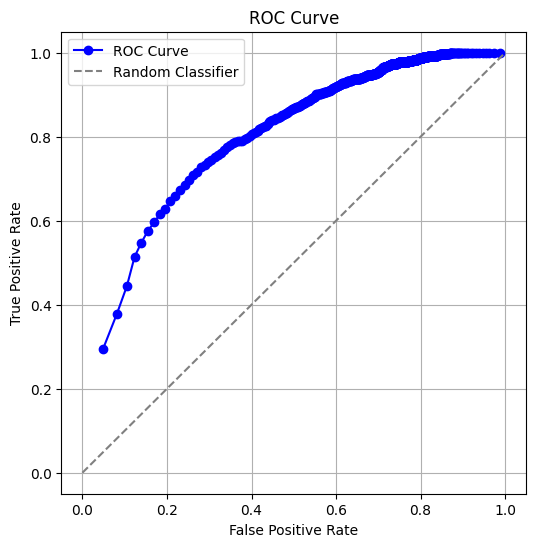

In [17]:
# codecell_4e (keep this id for tracking purposes)

y_scores, y_pred = make_predictions(lr_classifier, X_test)

# If you need to, adjust thresholds.
_ = plot_roc_curve(y_scores, y_test, thresholds = [i / 1000.0 for i in range(1, 1000)])

Plot the ROC curve for `sgd_classifier` below.

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

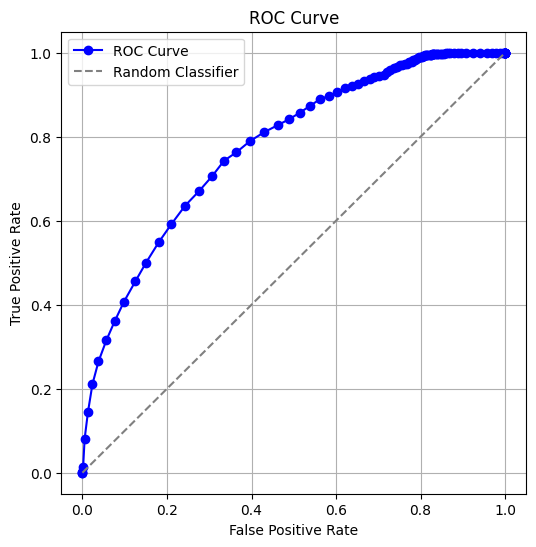

In [18]:
# codecell_4f (keep this id for tracking purposes)

y_scores, y_pred = make_predictions(sgd_classifier, X_test)

# If you need to, adjust thresholds.
_ = plot_roc_curve(y_scores, y_test, thresholds = [i / 100.0 for i in range(1, 100)])

Plot the ROC curve for `mystery_classifier` below.

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

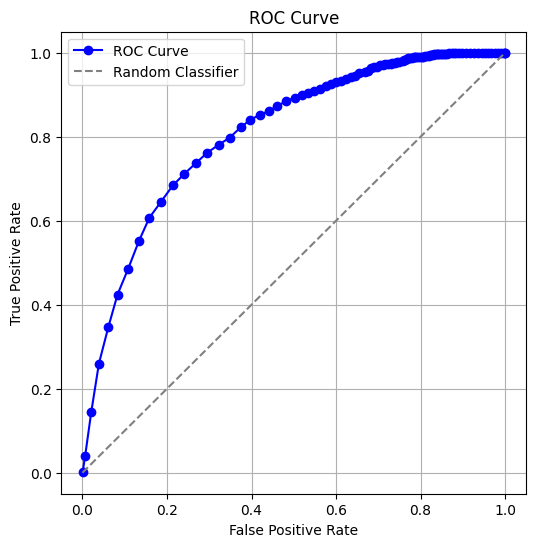

In [19]:
# codecell_4g (keep this id for tracking purposes)

from sklearn.svm import SVC

# Create and train SVM classifier (enable probability=True to get scores)
mystery_classifier = SVC(kernel='linear', probability=True, random_state=0)
mystery_classifier.fit(X_train, y_train)

# Get predictions and scores using your helper
y_scores, y_pred = make_predictions(mystery_classifier, X_test)

# If you need to, adjust thresholds.
_ = plot_roc_curve(y_scores, y_test, thresholds = [i / 100.0 for i in range(1, 100)])

Plot the ROC curves for all three classifiers (overlaid on the same graph, different colors) below.

<font color="red">**In your assignment submission, please make sure we can clearly see the output of the following cell.**</font>

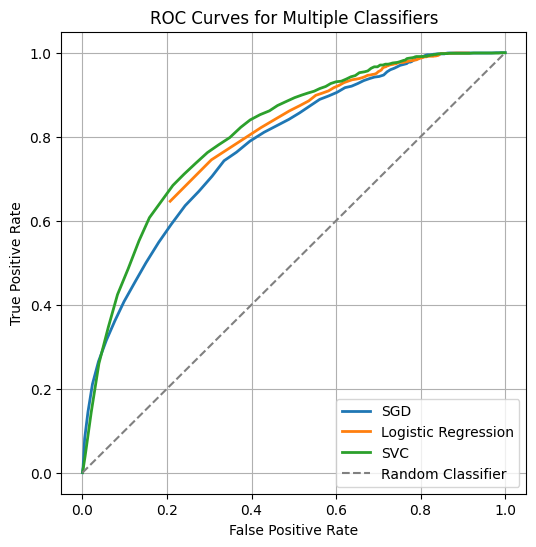

In [ ]:
# codecell_4h (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.


def plot_roc_curve_multiple(classifiers, classifier_names, X_test, y_test, thresholds=None):
    import matplotlib.pyplot as plt
    import numpy as np

    if thresholds is None:
        thresholds = np.linspace(0, 1, 101)

    plt.figure(figsize=(6,6))

    for clf, name in zip(classifiers, classifier_names):
        scores, _ = make_predictions(clf, X_test)
        scores = np.array(scores)
        y_true = np.array(y_test)

        tpr_list = []
        fpr_list = []

        for thresh in thresholds:
            y_pred = (scores >= thresh).astype(int)

            TP = np.sum((y_pred == 1)&(y_true == 1))
            FP = np.sum((y_pred == 1)&(y_true == 0))
            FN = np.sum((y_pred == 0)&(y_true == 1))
            TN = np.sum((y_pred == 0)&(y_true == 0))

            TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
            FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

            tpr_list.append(TPR)
            fpr_list.append(FPR)

        plt.plot(fpr_list, tpr_list, linestyle='-', lw=2, label=f'{name}')

    # Random classifier line
    plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Multiple Classifiers')
    plt.legend()
    plt.grid(True)
    plt.show()

classifiers = [sgd_classifier, lr_classifier, mystery_classifier]
classifier_names = ['SGD', 'Logistic Regression', 'SVC']

plot_roc_curve_multiple(classifiers, classifier_names, X_test, y_test, thresholds=[i/100.0 for i in range(1,100)])


<font color="red">**Answer the questions below!**</font>

// qcell_4qx2 (keep this id for tracking purposes)

**Q4.2** What do the ROC curves tell you about the differences between the output classification quality of the three classifiers?

<font color="red">**Your answer here.**</font> \
All 3 classifiers perform similarly. SVC permorms marginally better across the middle threshold range with better TP and FP rates and clearly has the highest AUC. SGD just beats out logistic regression, but neither of the models is remarkably different from the other ones.

## 5. Exploring SGD Non-Determinism with `scikit-learn`

Go back and run the (wrapped) `SGDClassifier` training and evaluate the predictions again.

Do you get the same results (say, AUC)?

Let's explore this a bit more. In the following cell, train 5 different `SGDClassifier` instances.
Use the "wrapped" version - just copy the code above.
At the end of the training process, they should all be in the array `classifiers`.

<font color="red">**Below, you'll have to write some code!**</font>

In [26]:
# codecell_5a (keep this id for tracking purposes)

classifiers = []

# TODO: Write your code below, but do not remove any lines already in this cell.
for i in range(5):
    sgd_base = SGDClassifier(loss="log_loss")
    sgd_classifier = CalibratedClassifierCV(sgd_base, method='sigmoid')
    sgd_classifier.fit(X_train, y_train)

    classifiers.append(sgd_classifier)


i = 0
for classifier in classifiers:
    print(f"Classifier {i}: {classifier}")
    i = i + 1

Classifier 0: CalibratedClassifierCV(estimator=SGDClassifier(loss='log_loss'))
Classifier 1: CalibratedClassifierCV(estimator=SGDClassifier(loss='log_loss'))
Classifier 2: CalibratedClassifierCV(estimator=SGDClassifier(loss='log_loss'))
Classifier 3: CalibratedClassifierCV(estimator=SGDClassifier(loss='log_loss'))
Classifier 4: CalibratedClassifierCV(estimator=SGDClassifier(loss='log_loss'))


Let's evaluate each of these classifiers.

The output for running the following cell should be something like this:

```
Classifier 0: AUC = 0.XXXX
Classifier 1: AUC = 0.XXXX
Classifier 2: AUC = 0.XXXX
...
```

<font color="red">**Below, you'll have to write some code!**</font>

In [27]:
# codecell_5b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
from sklearn.metrics import roc_auc_score

# Evaluate each classifier
for i, clf in enumerate(classifiers):
    y_scores, y_pred = make_predictions(clf, X_test)
    auc = roc_auc_score(y_test, y_scores)
    print(f"Classifier {i}: AUC = {auc:.4f}")


Classifier 0: AUC = 0.7718
Classifier 1: AUC = 0.7836
Classifier 2: AUC = 0.7710
Classifier 3: AUC = 0.7988
Classifier 4: AUC = 0.7729


Confirm that each classifier does indeed indeed have a different AUC.
That is, same dataset, different training instances lead to different AUC metrics.

The next obvious question: Is there any way to combine the classifiers?
The technical term for this is to ensemble the three different classifiers.

One very simple way is just to average the scores from each classifier instance.
That is, you get a score out of each of the classifier instances... so let's just average the scores.

Implement this below and compute the AUC of simple score averaging.

<font color="red">**Below, you'll have to write some code!**</font>

In [28]:
# codecell_5c (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
all_scores = []

for clf in classifiers:
    y_scores, _ = make_predictions(clf, X_test)
    all_scores.append(np.array(y_scores))

all_scores = np.array(all_scores)

avg_scores = np.mean(all_scores, axis=0)

auc = roc_auc_score(y_test, avg_scores)
print(f"{i}-classifier ensemble using score-averaging: AUC = {auc:.4f}")

4-classifier ensemble using score-averaging: AUC = 0.7826


<font color="red">**Answer the questions below!**</font>


// qcell_5qx (keep this id for tracking purposes)

**Q5a** What do you observe about the AUC of the score-averaging ensemble, compared to the best individual model and the worst individual model?

<font color="red">**Your answer here.**</font> \
It is comparable to the best individual model. Across multiple runs the ensemble model was always just better or just worse than the best individual model and each time above the average individual model.

**Q5b** Why would using this simple score-averaging ensemble be better than using any individual model?

<font color="red">**Your answer here.**</font> \
It will catch the weaknesses of any individual model by averaging the scores. So, the hope is that when a single model makes a mistake it will be outweighted by the average of all the other ones. Essentially a robust protection against simple one off mistakes. 

**Q5c** Are there any downsides to prediction using this simple score-averaging ensemble?

<font color="red">**Your answer here.**</font> \
Good predictions from a few can also be dragged down by bad preditctions of the other ones. It takes more copmute resources while not necessarily improving the quality of the model.

## 6. Effect of Different Dataset Sizes

How does the AUC change given the amount training data we use?
Let's do some exploration to find out, using the `LogisticRegression` classifier.

Here's the plot we're after:
+ on the _x_ axis, plot the fraction of training data we use.
+ on the _y_ axis, plot the AUC.

Let's explore using the following fractions of the training data: `[0.1, 0.25, 0.50, 0.75, 0.90, 1.0]`

That is, we sample (say 10%) of the training data, train a classifier, and measure its AUC on the test data.
Since each trial is going to be noisy, let's run each sampling rate 3 times and average the AUC across them.
That is, 3 trials at 10% sample, 3 trial at 25% sample, etc.

Plot the graph described above.

<font color="red">**Below, you'll have to write some code. 
In your submission, please make sure we can clearly see the output of running the code.**</font>

Note that when grading we're not going to be too picky about the code; what we're after is the actual plot.

Started
Fraction 0.10 → Mean AUC = 0.7104 ± 0.0043
Fraction 0.25 → Mean AUC = 0.7488 ± 0.0147
Fraction 0.50 → Mean AUC = 0.7812 ± 0.0045
Fraction 0.75 → Mean AUC = 0.7884 ± 0.0017
Fraction 0.90 → Mean AUC = 0.7914 ± 0.0026
Fraction 1.00 → Mean AUC = 0.7935 ± 0.0003


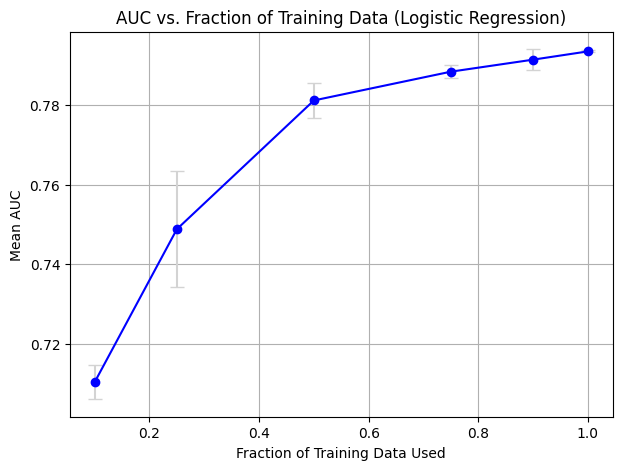

In [24]:
# codecell_6a (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

fractions = [0.1, 0.25, 0.50, 0.75, 0.90, 1.0]
num_trials = 3

mean_aucs = []
std_aucs = []
print("Started")
for i, fraction in enumerate(fractions):
    aucs = []

    for trial in range(num_trials):
        X_sample, y_sample = resample(
            X_train, y_train,
            replace=False,
            n_samples=int(X_train.shape[0] * fraction),
            random_state=trial
        )

        lr_classifier = LogisticRegression(solver="saga", penalty="l2", max_iter=2000)
        lr_classifier.fit(X_sample, y_sample)

        y_scores, y_pred = make_predictions(lr_classifier, X_test)
        #print("looped")

        auc = roc_auc_score(y_test, y_scores)
        aucs.append(auc)

    mean_auc = np.mean(aucs)
    std_auc = np.std(aucs)
    mean_aucs.append(mean_auc)
    std_aucs.append(std_auc)

    print(f"Fraction {fraction:.2f} → Mean AUC = {mean_auc:.4f} ± {std_auc:.4f}")

# Plot mean AUC with error bars
plt.figure(figsize=(7,5))
plt.errorbar(fractions, mean_aucs, yerr=std_aucs, fmt='-o', color='blue', ecolor='lightgray', capsize=5)
plt.xlabel('Fraction of Training Data Used')
plt.ylabel('Mean AUC')
plt.title('AUC vs. Fraction of Training Data (Logistic Regression)')
plt.grid(True)
plt.show()


// qcell_6qx (keep this id for tracking purposes)

**Q6** What relationship do you observe between the amount of training data used and the classifier output quality?

<font color="red">**Your answer here.**</font> \
More training data always improves performance even in the later stages, but after a point, the gains become minimal. In here the cutoff point for diminishing returns seems to be after the jump from 0.5 to 0.75.  



That's it for this assignment!